In [1]:
# setup

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

con = duckdb.connect()
con.sql("SET enable_progress_bar = false") # prevent progress bars from showing up
con.sql("CREATE VIEW business AS SELECT * FROM '../data/processed/business.parquet'")
con.sql("CREATE VIEW review AS SELECT * FROM '../data/processed/review.parquet'")

# business as a pd dataframe (use SQL and pandas to profile! yay)
business = con.sql("SELECT * FROM business").df()

In [2]:
# looking at columns

print(business.columns)

columns_r = con.sql('SELECT * FROM review').columns
print(columns_r)

Index(['business_id', 'name', 'address', 'city', 'state', 'postal_code',
       'latitude', 'longitude', 'stars', 'review_count', 'is_open',
       'attributes', 'categories', 'hours'],
      dtype='str')
['review_id', 'user_id', 'business_id', 'stars', 'useful', 'funny', 'cool', 'text', 'date']


In [3]:
# how many reviews are there, and in what date range?

# review count
r_count = con.sql('SELECT COUNT(*) FROM review').fetchone()[0]
print(f'Review count: {r_count:,}')

# date range
r_dmin, r_dmax = con.sql('SELECT MIN(date), MAX(date) FROM review').fetchone()
print(f'date dtype: {type(r_dmin)}')
print(f'MIN date: {r_dmin}')
print(f'MAX date: {r_dmax}')

Review count: 6,990,280
date dtype: <class 'datetime.datetime'>
MIN date: 2005-02-16 03:23:22
MAX date: 2022-01-19 19:48:45


__1. reviews and date range__
1. Reviews: 6,990,280 total
2. Date range: Feb 2005 - Jan 2022

Date range includes COVID data. Dates stored as datetime.datetime

In [4]:
# how many restaurants? how many businesses have no categories?

# restaurant count
b_rest = business[business['categories'].str.contains('Restaurants', na=False)]
print(f'Restaurant count: {b_rest.shape[0]:,}')

# businesses tagged "Food" but not "Restaurants"
cats = business["categories"]
has_food = cats.str.contains("Food", na=False)
has_rest = cats.str.contains("Restaurants", na=False)

food_only = business[has_food & ~has_rest]
print(f"\nNumber of businesses marked as Food but not Restaurants: {len(food_only)}")

# most common categories among them
top_cats = (
    food_only["categories"]
    .str.split(", ")
    .explode()
    .value_counts()
    .drop("Food", errors="ignore")
    .head(15)
)
print(top_cats)

# counting empty categories 
text_cols = ["name", "address", "city", "state", "postal_code", "categories"]
b = business[text_cols]

missing = pd.DataFrame({
    "nulls": b.isna().sum(),
    "empty": (b == "").sum(),
    "whitespace_only": b.apply(lambda s: ((s.str.strip() == "") & (s != "")).sum()),
})
print(f'\nMissing data counts by column: \n{missing}')

Restaurant count: 52,268

Number of businesses marked as Food but not Restaurants: 12348
categories
Shopping                     2750
Coffee & Tea                 2650
Grocery                      2312
Specialty Food               2222
Ice Cream & Frozen Yogurt    1569
Convenience Stores           1384
Desserts                     1348
Drugstores                   1319
Bakeries                     1261
Beer                         1259
Wine & Spirits               1259
Juice Bars & Smoothies        669
Donuts                        622
Nightlife                     603
Health & Medical              566
Name: count, dtype: int64

Missing data counts by column: 
             nulls  empty  whitespace_only
name             0      0                0
address          0   5127                0
city             0      0                0
state            0      0                0
postal_code      0     73                0
categories     103      0                0


__2. restaurant count, businesses with no categories__
1. Restaurants: 52,268 total. 

Analyzing restaurants only. Businesses with food-only categories (no restaurant) appear to be grocery, coffee shops and convenience stores, which don't fit questions about meal quality. 12,348 businesses are tagged Food but not Restaurants. Top categories are Shopping (2,750), Coffee & Tea (2,650), Grocery (2,312), etc.

2. 5,127 empty values under address, 73 under postal_code, and 103 nulls for categories.

Missing values are stored inconsistently: empty strings in address and postal code, nulls in categories. A null-only check would report address as complete. 

Standardize empty strings to null in src/clean.py.

In [5]:
# how many reviews belong to restaurants?

rb_count = con.sql("""SELECT COUNT (*) FROM review r 
                    JOIN business b ON r.business_id = b.business_id
                    WHERE b.categories LIKE '%Restaurants%'""").fetchone()[0]

print(f'Restaurant review count: {rb_count:,}')
print(f'% of total review count: {rb_count/r_count :.2%}')

Restaurant review count: 4,724,471
% of total review count: 67.59%


__3. reviews belonging to restaurants__
1. Yelp dataset has 4,724,471 reviews belonging to restaurants, which is about 67.6% of all reviews.

In [6]:
# checking missing values for restaurants:

b_r = b_rest[text_cols]

missing = pd.DataFrame({
    "nulls": b_r.isna().sum(),
    "empty": (b_r == "").sum(),
    "whitespace_only": b_r.apply(lambda s: ((s.str.strip() == "") & (s != "")).sum()),
})
print(f'\nRestaurant missing data counts by column: \n{missing}')


Restaurant missing data counts by column: 
             nulls  empty  whitespace_only
name             0      0                0
address          0    443                0
city             0      0                0
state            0      0                0
postal_code      0     21                0
categories       0      0                0


__4. Missing restaurant data__

1. There are 443 missing address entries and 21 missing postal codes for the restaurants in the dataset before cleaning. 

Out of ~52k restaurants, 443 missing address entries is ~0.85% of all restaurants (problem is minor).

This data is not too important for analysis, though they could be used to differentiate between locations of the same chain restaurant. Note that categories is 0 because restaurants are selected by category.

Restaurant review count quantiles:
0.25     13.00
0.50     33.00
0.75     89.00
0.90    207.00
0.99    757.66
Name: review_count, dtype: float64
Mean review count: 87.3
Min review count: 5
Max review count: 7,568
16.19% of restaurants have under 10 reviews
35.06% of restaurants have under 20 reviews


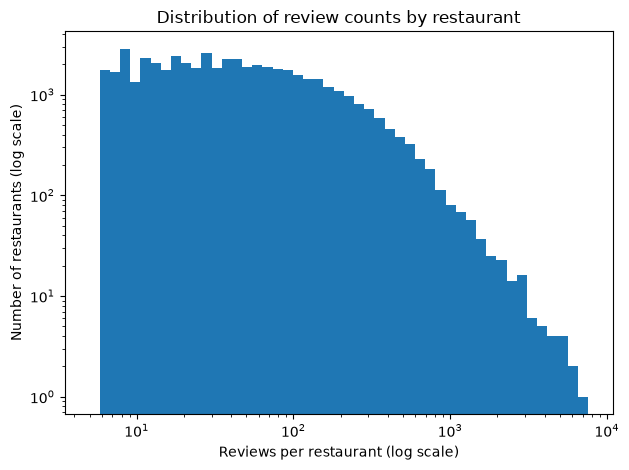

In [7]:
# how are reviews spread across restaurants? (distribution)
rev_counts = b_rest['review_count']

# quartile analysis
print(f'Restaurant review count quantiles:\n{rev_counts.quantile([.25, .5, .75, .9, .99])}')
print(f'Mean review count: {rev_counts.mean():.1f}')
print(f'Min review count: {rev_counts.min()}')
print(f'Max review count: {rev_counts.max():,}')

# small count freq
print(f'{(rev_counts <10).mean() :.2%} of restaurants have under 10 reviews')
print(f'{(rev_counts <20).mean() :.2%} of restaurants have under 20 reviews')

# plot histogram with log-spaced bins
bins = np.logspace(np.log10(rev_counts.min()), np.log10(rev_counts.max()), 50)

plt.hist(rev_counts, bins=bins)
plt.xscale('log')
plt.yscale('log')
plt.title('Distribution of review counts by restaurant')
plt.xlabel('Reviews per restaurant (log scale)')
plt.ylabel('Number of restaurants (log scale)')
plt.tight_layout()
plt.show()

__5. Review counts by restaurant__

1. Quantiles for 25%, 50%, 75%, 90%, and 99% are 13, 33, 89, 207, and 758 (99th rounded from 757.66).

Median=33, mean=87.3: the mean is about 2.6x the median, indicating a few popular restaurants with high review counts pulling up the average. 90% of restaurants have 207 or fewer reviews and 99% have about 758 or fewer, but the max is 7,568. This is the long tail of the distribution (visualized by plot). Note the minimum is 5: the Yelp dataset appears to only include businesses with at least 5 reviews. This is a limitation of the dataset: very new or barely reviewed restaurants do not appear. 

16% of restaurants have fewer than 10 reviews and 35% have fewer than 20. About a third of restaurants have ratings based on few opinions. This supports the usage of Bayesian shrinkage to pull to chain averages, and for independent restaurants, shrinking to a broader target average (e.g. location, category, etc.) to be determined later in the pipeline. 

In [8]:
# matching review counts from business to reviews

matches, yelp_higher, file_higher = con.sql("""
    SELECT
        COUNT(*) FILTER (WHERE b.review_count = r.n) AS matches,
        COUNT(*) FILTER (WHERE b.review_count > r.n) AS yelp_higher,
        COUNT(*) FILTER (WHERE b.review_count < r.n) AS file_higher
    FROM business b
    JOIN (SELECT business_id, COUNT(*) AS n FROM review GROUP BY business_id) r
      ON b.business_id = r.business_id
    WHERE b.categories LIKE '%Restaurants%'
""").fetchone()

print(f"Stored count matches actual reviews: {matches:,}")
print(f"Yelp's stored count is higher: {yelp_higher:,}")
print(f"Review file has more than stored: {file_higher:,}")

Stored count matches actual reviews: 20,250
Yelp's stored count is higher: 6
Review file has more than stored: 32,012


__6. Does stored review_count match review file?__

1. Stored review_count matches the review file for only 39% of restaurants (20,250). 61% (32,012) have more reviews in the file than stored, and only 6 have fewer. Nearly every mismatch is in the same direction (file > stored), so there is likely a specific cause rather than random error. Investigating gap size and possible duplicate reviews next.

In [9]:
# q6 follow up: how big are the gaps between stored and actual review counts?

gaps = con.sql("""
    SELECT
        b.business_id,
        b.review_count       AS stored,
        r.n                  AS actual,
        r.n - b.review_count AS gap
    FROM business b
    JOIN (SELECT business_id, COUNT(*) AS n FROM review GROUP BY business_id) r
      ON b.business_id = r.business_id
    WHERE b.categories LIKE '%Restaurants%'
      AND r.n <> b.review_count
""").df()

print(f"Restaurants with a mismatch: {len(gaps):,}")
print(f"\nGap size (actual - stored):\n{gaps['gap'].describe(percentiles=[.25, .5, .75, .9, .99])}")

# gap relative to the stored count, e.g. 0.05 = file has 5% more reviews than stored
gaps['gap_pct'] = gaps['gap'] / gaps['stored']
print(f"\nMedian gap as % of stored count: {gaps['gap_pct'].median():.1%}")

total_extra = gaps.loc[gaps['gap'] > 0, 'gap'].sum()
print(f"Total extra reviews in file across restaurants: {total_extra:,}")

Restaurants with a mismatch: 32,018

Gap size (actual - stored):
count    32018.000000
mean         5.096883
std          7.168533
min         -1.000000
25%          1.000000
50%          3.000000
75%          6.000000
90%         12.000000
99%         35.000000
max        128.000000
Name: gap, dtype: float64

Median gap as % of stored count: 4.4%
Total extra reviews in file across restaurants: 163,198


In [10]:
# q6 follow up 2: are there duplicate reviews?

# check 1: are review_ids unique
total, distinct_ids = con.sql(
    "SELECT COUNT(*), COUNT(DISTINCT review_id) FROM review"
).fetchone()
print(f"Reviews: {total:,}   distinct review_ids: {distinct_ids:,}   repeated ids: {total - distinct_ids:,}")

# check 2: same user, same restaurant, same date, same text -> a copy, even if the id differs
dup_groups, extra_rows = con.sql("""
    SELECT COUNT(*) AS dup_groups, COALESCE(SUM(n - 1), 0) AS extra_rows
    FROM (
        SELECT COUNT(*) AS n
        FROM review r
        JOIN business b ON r.business_id = b.business_id
        WHERE b.categories LIKE '%Restaurants%'
        GROUP BY r.user_id, r.business_id, r.date, hash(r.text)
        HAVING COUNT(*) > 1
    )
""").fetchone()
print(f"Restaurant reviews duplicated by content: {dup_groups:,} groups, {extra_rows:,} extra copies")

# check 3: same user reviewing the same restaurant more than once (any date or text)
multi_groups, multi_extra = con.sql("""
    SELECT COUNT(*) AS groups, COALESCE(SUM(n - 1), 0) AS extra_rows
    FROM (
        SELECT COUNT(*) AS n
        FROM review r
        JOIN business b ON r.business_id = b.business_id
        WHERE b.categories LIKE '%Restaurants%'
        GROUP BY r.user_id, r.business_id
        HAVING COUNT(*) > 1
    )
""").fetchone()
print(f"Same user, same restaurant, multiple reviews: {multi_groups:,} pairs, {multi_extra:,} extra rows")

Reviews: 6,990,280   distinct review_ids: 6,990,280   repeated ids: 0
Restaurant reviews duplicated by content: 3 groups, 4 extra copies
Same user, same restaurant, multiple reviews: 141,830 pairs, 163,029 extra rows


In [11]:
# q6 follow up 3: does review_count = number of distinct users per restaurant?
# this stems from the number of repeat reviews from the same user at the same restaurant found in follow up 2

d_matches, d_yelp_higher, d_users_higher = con.sql("""
    SELECT
        COUNT(*) FILTER (WHERE b.review_count = r.users) AS matches,
        COUNT(*) FILTER (WHERE b.review_count > r.users) AS yelp_higher,
        COUNT(*) FILTER (WHERE b.review_count < r.users) AS users_higher
    FROM business b
    JOIN (
        SELECT business_id, COUNT(DISTINCT user_id) AS users
        FROM review
        GROUP BY business_id
    ) r
      ON b.business_id = r.business_id
    WHERE b.categories LIKE '%Restaurants%'
""").fetchone()

total_rest = d_matches + d_yelp_higher + d_users_higher
print(f"Stored count = distinct users: {d_matches:,} ({d_matches / total_rest:.2%})")
print(f"Stored count higher:           {d_yelp_higher:,}")
print(f"Distinct users higher:         {d_users_higher:,}")

Stored count = distinct users: 52,084 (99.65%)
Stored count higher:           12
Distinct users higher:         172


__6.1 Follow up: Cause for mismatch & proposed action__

1. Mismatches between the stored review_count and the actual reviews in the file are small: median gap of 3 reviews (4.4% of stored count), with 90% of all records within 12. In total the file has 163,198 more restaurant reviews (~3.5%) than the stored business counts. 
2. Duplicates don't explain it (follow up q2): review_ids are all unique, and only 4 exact duplicate rows exist (same user, restaurant, time and text). 
3. Repeat reviews: 141,830 user/restaurant pairs have more than one review, accounting for 163,029 extra rows, which makes up almost all of the 163,198 gap. Confirmed per restaurant: stored review_count equals the number of distinct reviewers for 99.65% of restaurants (up from 39% when counting all reviews). Conclusion: review_count counts reviewers, not reviews. 
4. Later analysis should count directly from the review file. Whether to keep all repeat reviews or one per user is a Phase 2 (cleaning) decision.
5. The 4 exact duplicates will be dropped in clean.py during cleaning.